# Common, partially comparable and unique features: School vs university

**Research questions:** (1) Which feature concepts are common, only loosely related, or unique? (2) Which input directions explain variation according to PCA? (3) How well do **the same small PyTorch neural networks** predict outcomes when trained using *common*, *common + cautiously comparable*, *common + exploratory weak analogues*, and *full baseline* variables? (4) Does feeding **PCA components** to the network improve prediction?

**Essential outcome warning:** Portuguese-school prediction is **course failure** (`G3 < 10`), **not real school dropout**. The separate university outcomes are `Dropout` / `Enrolled` / `Graduate`. These outcomes must never be pooled or scored as one target. Models are trained **separately** on each population. PCA is **unsupervised variance analysis**, not proof of target predictiveness or causality.

## Methodology & leakage controls

- Use 649 **Portuguese anchor** records for the school experiment (avoid classifying 25 extra mathematics anchors as an independent full cohort); match `student_id` to `student_outcomes_reference.csv`.
- University experiment uses 4,424 enrollment feature rows, joined to the `Target` column only. We never use later semester grades, semester credits or outcomes as features.
- Reuse **original `split` columns**. Group lineage must not cross train/validation/test. For the resolved-case university task, discard `Enrolled`, **not** assign it to graduate.
- Feature groups are **within-dataset analogues**, **not numeric harmonization**. Education and occupation coding differ across datasets; categorical codes are one-hot encoded independently. Sex/gender semantics also differ; sensitive attributes are used only to explore predictive signals, not to justify allocation decisions.
- **Cautious partial**: academic achievement/history proxies. Comparable broad idea, *different timing and scales*; no cross-population transfer claims.
- **Weak exploratory partial**: home-internet proxy versus scholarship status; school support versus university special-education-needs flag. These are **not equivalent**, and university scholarship timing relative to enrollment is unverified. Keep them out of the strict early-prediction conclusion.
- We do **not** map `source_total_absences_count` to `Daytime/evening attendance`: absence count is accumulated attendance history, while the university field is study schedule. Nor map parental separation to student's marital status. We record them as unique / rejected analogues.
- Fit imputers, encoders, scalers and PCA **on training rows only**. Choose training checkpoint via validation loss; do not choose hyperparameters or feature groups from test scores.
- Evaluate dropout/failure class PR-AUC, ROC-AUC, macro-F1, positive recall, Brier score and accuracy; use one reproducible seed. The small school holdout requires caution.

In [1]:
from pathlib import Path
from io import BytesIO
import os, random, zipfile, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, roc_auc_score, accuracy_score, f1_score, recall_score, brier_score_loss, confusion_matrix
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display

SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(2, torch.get_num_threads()))

project_root = Path.cwd()
while project_root != project_root.parent and not (project_root / "data" / "external").is_dir():
    project_root = project_root.parent

OUTPUT_DIR = Path(project_root / 'outputs' / 'common_feature_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load and verify the two independent datasets

In [2]:
def read_data(path):
    return pd.read_csv(path, low_memory=False)


school_features = read_data(project_root / 'data' /'processed/students/student_dataset.csv')
school_outcomes = read_data(project_root / 'data' / 'external/student_outcomes_reference.csv')
university_features = read_data(project_root / 'data' / 'external/higher_ed_enrollment_features.csv')
university_outcomes = read_data(project_root / 'data' / 'external/higher_ed_outcomes_reference.csv')

assert len(school_features)==len(school_outcomes)==674
assert len(university_features)==len(university_outcomes)==4424
assert school_features.student_id.is_unique and school_outcomes.student_id.is_unique
assert university_features.record_id.is_unique and university_outcomes.record_id.is_unique
school = school_features.merge(school_outcomes[['student_id','anchor_course_failure_proxy','anchor_final_grade_0_20']],on='student_id',validate='one_to_one')
school = school.loc[school.anchor_subject.eq('portuguese')].copy()
univ = university_features.merge(university_outcomes[['record_id','Target']],on='record_id',validate='one_to_one')
assert len(school)==649 and len(univ)==4424
assert (school.anchor_course_failure_proxy == (school.anchor_final_grade_0_20 < 10).astype(int)).all()
assert school.observed_school_dropout.isna().all()
assert set(univ.Target.unique())=={'Dropout','Enrolled','Graduate'}
for name,d in [('School Portuguese',school),('University',univ)]:
    ids = [set(d.loc[d.split==s,'linkage_group_id']) for s in ('train','validation','test')]
    assert not(ids[0]&ids[1] or ids[0]&ids[2] or ids[1]&ids[2])
    print(name, 'rows',len(d),'train/validation/test',d.split.value_counts().to_dict())
print('School final-course-failure',school.anchor_course_failure_proxy.value_counts().to_dict())
print('University outcomes',univ.Target.value_counts().to_dict())

School Portuguese rows 649 train/validation/test {'train': 388, 'test': 136, 'validation': 125}
University rows 4424 train/validation/test {'train': 2658, 'test': 908, 'validation': 858}
School final-course-failure {0: 549, 1: 100}
University outcomes {'Graduate': 2209, 'Dropout': 1421, 'Enrolled': 794}


## Explicit feature concept map

This is a **semantic mapping**, not an exact-column-name intersection. Each matched concept records whether it is `common`, `partial_cautious`, or `partial_weak`. The remaining columns are classified as `unique` or excluded administrative/target/leakage fields. `partial_weak` fields are **not matched measurements** and are intentionally a separate stress-test experiment.

In [3]:
# category: common = close concept; partial_cautious = broad academic-history analogue;
# partial_weak = related contexts but NOT equivalent measurements.
MAP = [
 ('Age','common','age_years','Age at enrollment','Age at enrollment and age in school have different reference dates.'),
 ('Sex / gender','common','sex_source','Gender','Recorded sex and gender may differ in definition; retain independent categorical encoding; sensitive variable.'),
 ('Mother education','common','mother_education_code',"Mother's qualification",'Ordinal school categories versus detailed university codes; do not equate numeric codes.'),
 ('Father education','common','father_education_code',"Father's qualification",'Different qualification categories and level coding.'),
 ('Mother occupation','common','mother_job',"Mother's occupation",'Broad school categories versus detailed university occupation categories.'),
 ('Father occupation','common','father_job',"Father's occupation",'Broad school categories versus detailed university occupation categories.'),
 ('Academic attainment','partial_cautious','anchor_grade1_0_20','Admission grade','School first-period grade versus prior admission mark; stage/timing/scale differ.'),
 ('Prior academic history','partial_cautious','past_failures_count','Previous qualification (grade)','Prior failures count versus previous qualification score; not directly comparable difficulty measures.'),
 ('Economic/access context','partial_weak','no_home_internet','Scholarship holder','No home internet versus scholarship status: different constructs; scholarship timing not established.'),
 ('Learning support context','partial_weak','school_support_existing','Educational special needs','Support received versus reported special needs: distinct constructs and sensitive status.'),
]
feature_map = pd.DataFrame(MAP,columns=['feature_concept','category','school_column','university_column','limitation'])
for row in feature_map.itertuples():
    assert row.school_column in school.columns,row.school_column
    assert row.university_column in univ.columns,row.university_column
assert not feature_map.school_column.duplicated().any()
assert not feature_map.university_column.duplicated().any()
feature_map.to_csv(OUTPUT_DIR/'common_partial_feature_mapping.csv',index=False)
display(feature_map)
print('Concepts by category:', feature_map.category.value_counts().to_dict())

,feature_concept,category,school_column,university_column,limitation
0,Age,common,age_years,Age at enrollment,Age at enrollment and age in school have diffe...
1,Sex / gender,common,sex_source,Gender,Recorded sex and gender may differ in definiti...
2,Mother education,common,mother_education_code,Mother's qualification,Ordinal school categories versus detailed univ...
3,Father education,common,father_education_code,Father's qualification,Different qualification categories and level c...
4,Mother occupation,common,mother_job,Mother's occupation,Broad school categories versus detailed univer...
5,Father occupation,common,father_job,Father's occupation,Broad school categories versus detailed univer...
6,Academic attainment,partial_cautious,anchor_grade1_0_20,Admission grade,School first-period grade versus prior admissi...
7,Prior academic history,partial_cautious,past_failures_count,Previous qualification (grade),Prior failures count versus previous qualifica...
8,Economic/access context,partial_weak,no_home_internet,Scholarship holder,No home internet versus scholarship status: di...
9,Learning support context,partial_weak,school_support_existing,Educational special needs,Support received versus reported special needs...


Concepts by category: {'common': 6, 'partial_cautious': 2, 'partial_weak': 2}


### Rejected analogues (kept distinct)

- `parents_apart` describes parents' relationship; `Marital status` describes the university student's marriage status.
- `source_total_absences_count` is a later cumulative count; `Daytime/evening attendance` is the university timetable mode.
- `school_support_existing` records support received; university `Educational special needs` indicates needs rather than support. Used only as **weak exploratory context**, not true equivalence.
- `Displaced` has no matching school mobility concept.
- `observed_school_dropout` has **all null** values; there is no school dropout target.
- Future university semester performance is **excluded from all baseline features**.

## All common, partial and unique features, including source-specific columns

The output CSV lists every original column exactly once per dataset, with a role and inclusion status. Note that `linkage_group_id`, `split` and IDs are metadata, not usable predictors. Derived school disadvantage fields should not be counted as independent evidence of poverty. Unique predictor lists are source-specific and do **not** imply equivalent target definitions.

In [4]:
SCHOOL_CATS = [
 'school_id','rural_residence','family_size_gt3','parents_apart','mother_education_code',
 'father_education_code','mother_job','father_job','guardian','travel_time_category',
 'study_time_category','school_support_existing','family_support_existing','paid_classes_existing',
 'extracurricular','nursery_attended','higher_education_aspiration','internet_at_home',
 'family_relationship_rating','health_self_rating','sex_source','no_home_internet'
]
SCHOOL_NUMS = ['age_years','past_failures_count','anchor_grade1_0_20']
UNIV_CATS = [
 'Marital status','Application mode','Course','Daytime/evening attendance',
 'Previous qualification','Nacionality',"Mother's qualification","Father's qualification",
 "Mother's occupation","Father's occupation",'Displaced', 'Educational special needs',
 'Gender','Scholarship holder','International'
]
UNIV_NUMS = ['Age at enrollment','Application order','Previous qualification (grade)',
             'Admission grade','Unemployment rate','Inflation rate','GDP']
# Financial fields 'Debtor', 'Tuition fees up to date' are intentionally excluded because
# their availability at the enrollment prediction landmark is unverified.
SCHOOL_ELIGIBLE=set(SCHOOL_CATS+SCHOOL_NUMS)
UNIV_ELIGIBLE=set(UNIV_CATS+UNIV_NUMS)
# Strict university enrollment-time baseline excludes weak/timing-unclear inputs;
# they remain in the separate explicitly exploratory partial experiment.
UNIV_FULL_EARLY=UNIV_ELIGIBLE-{'Scholarship holder','Educational special needs'}
SCHOOL_LABELS={'observed_school_dropout','learning_gap_initial_assumed'}
UNIV_TIMING_UNKNOWN={'Debtor','Tuition fees up to date'}
SCHOOL_META={'student_id','linkage_group_id','split','source_dataset','population','anchor_subject','source_row','record_provenance','link_status'}
UNIV_META={'record_id','linkage_group_id','split'}
school_mapping={r.school_column:(r.feature_concept,r.category,r.limitation) for r in feature_map.itertuples()}
univ_mapping={r.university_column:(r.feature_concept,r.category,r.limitation) for r in feature_map.itertuples()}

def make_catalog(cols, source, matched, eligible, meta, unavailable):
    rows=[]
    for col in cols:
        if col in matched:
            concept,category,limitation=matched[col]
        elif col in meta:
            concept,category,limitation='','identifier_or_metadata','Not a predictive feature'
        elif col in unavailable:
            concept,category,limitation='','unavailable_or_derived_simulation','Missing, assumed, or simulator-derived—not an observed predictor'
        elif col in eligible:
            concept,category,limitation='','unique','No defensibly equivalent counterpart in the other data'
        else:
            concept,category,limitation='','excluded','Unavailable at landmark, derivative, or excluded by design'
        rows.append({'dataset':source,'column':col,'category':category,'concept':concept,
                     'in_candidate_features':col in eligible,'caveat':limitation})
    return rows
catalog=pd.DataFrame(make_catalog(school_features.columns,'school',school_mapping,SCHOOL_ELIGIBLE,SCHOOL_META,SCHOOL_LABELS)+
                     make_catalog(university_features.columns,'university',univ_mapping,UNIV_ELIGIBLE,UNIV_META,UNIV_TIMING_UNKNOWN))
assert len(catalog)==44+27
assert catalog.groupby(['dataset','column']).size().eq(1).all()
# Unique variables from the true columns, not synthetic aliases.
catalog.to_csv(OUTPUT_DIR/'all_features_common_partial_unique.csv',index=False)
display(catalog.groupby(['dataset','category']).size().unstack(fill_value=0))
for src in ('school','university'):
    print('\nUNIQUE PREDICTORS —',src)
    display(catalog.query('dataset==@src and category=="unique"')[['column']].reset_index(drop=True))
print('\nNot valid to call common simply because exact names match:')
print('Split and linkage IDs do not link school people to university people.')

category,common,excluded,identifier_or_metadata,partial_cautious,partial_weak,unavailable_or_derived_simulation,unique
dataset,,,,,,,
school,6,8,9,2,2,2,15
university,6,0,3,2,2,2,12



UNIQUE PREDICTORS — school


,column
0,school_id
1,rural_residence
2,family_size_gt3
3,parents_apart
4,guardian
5,travel_time_category
6,study_time_category
7,family_support_existing
8,paid_classes_existing
9,extracurricular



UNIQUE PREDICTORS — university


,column
0,Application order
1,Unemployment rate
2,Inflation rate
3,GDP
4,Marital status
5,Application mode
6,Course
7,Daytime/evening attendance
8,Previous qualification
9,Nacionality



Not valid to call common simply because exact names match:
Split and linkage IDs do not link school people to university people.


## Feature subsets to test

We train the **same** network architecture independently on each task using the following representations:

1. **Common only** — 6 shared concepts.
2. **Common + cautious partial** — six shared concepts + two broad academic-history concepts.
3. **Common + exploratory weak partial** — add the two **non-equivalent** financial/support indicators for sensitivity analysis (not a safe harmonized dataset).
4. **Full eligible** — source-specific *early-available* reference features. The university baseline excludes scholarship status and educational-special-needs status (both only in the exploratory experiment); it therefore need not be a superset of the exploratory group. This is a **within-dataset** baseline, not cross-dataset transfer.

Every set is tested both as preprocessed original columns and as training-fitted 95%-variance PCA components. A separate top-PCA-ranked-original-fields neural model is trained on the **common + cautious partial** subset.

In [5]:
SUBSETS = [
 ('common_only', ['common']),
 ('common_plus_cautious', ['common','partial_cautious']),
 ('common_plus_exploratory', ['common','partial_cautious','partial_weak']),
 ('full_eligible', None),
]

def cols_for_subset(dataset, label):
    if label=='full_eligible': return sorted(SCHOOL_ELIGIBLE if dataset=='school' else UNIV_FULL_EARLY)
    levels=dict(SUBSETS)[label]
    colname='school_column' if dataset=='school' else 'university_column'
    return feature_map.loc[feature_map.category.isin(levels),colname].tolist()
for src in ('school','university'):
    for subset,_ in SUBSETS:
        fields=cols_for_subset(src,subset)
        assert set(fields).issubset(SCHOOL_ELIGIBLE if src=='school' else UNIV_ELIGIBLE)
        print(src, subset, len(fields), fields)
selected_feature_rows=[]
for src in ('school','university'):
    for subset,_ in SUBSETS:
        for col in cols_for_subset(src,subset):
            selected_feature_rows.append({'dataset':src,'subset':subset,'column':col})
pd.DataFrame(selected_feature_rows).to_csv(OUTPUT_DIR/'feature_set_membership.csv',index=False)

school common_only 6 ['age_years', 'sex_source', 'mother_education_code', 'father_education_code', 'mother_job', 'father_job']
school common_plus_cautious 8 ['age_years', 'sex_source', 'mother_education_code', 'father_education_code', 'mother_job', 'father_job', 'anchor_grade1_0_20', 'past_failures_count']
school common_plus_exploratory 10 ['age_years', 'sex_source', 'mother_education_code', 'father_education_code', 'mother_job', 'father_job', 'anchor_grade1_0_20', 'past_failures_count', 'no_home_internet', 'school_support_existing']
school full_eligible 25 ['age_years', 'anchor_grade1_0_20', 'extracurricular', 'family_relationship_rating', 'family_size_gt3', 'family_support_existing', 'father_education_code', 'father_job', 'guardian', 'health_self_rating', 'higher_education_aspiration', 'internet_at_home', 'mother_education_code', 'mother_job', 'no_home_internet', 'nursery_attended', 'paid_classes_existing', 'parents_apart', 'past_failures_count', 'rural_residence', 'school_id', 'scho

## Prepare train / validation / test targets

Three tasks retain the previous benchmark's scope: university three-class status, university binary resolved cases, and Portuguese course failure. Labels are never features.

In [6]:
school=school.copy()
school['target_label']=school.anchor_course_failure_proxy.map({1:'Failure',0:'Pass'})
tasks={
 'university_three_class':{'df':univ,'dataset':'university','target':'Target','labels':['Dropout','Enrolled','Graduate']},
 'university_resolved_binary':{'df':univ[univ.Target.isin(['Dropout','Graduate'])].copy(),'dataset':'university','target':'Target','labels':['Dropout','Graduate']},
 'portuguese_course_failure':{'df':school,'dataset':'school','target':'target_label','labels':['Failure','Pass']}
}
for t,cfg in tasks.items():
    cfg['parts']={s:cfg['df'][cfg['df'].split==s].reset_index(drop=True) for s in ('train','validation','test')}
    cfg['ys']={s:cfg['parts'][s][cfg['target']].map({x:i for i,x in enumerate(cfg['labels'])}).to_numpy(dtype=np.int64) for s in cfg['parts']}
    assert all((y>=0).all() for y in cfg['ys'].values())
    print(t,{s:len(cfg['parts'][s]) for s in cfg['parts']},'training positives',(cfg['ys']['train']==0).sum())

university_three_class {'train': 2658, 'validation': 858, 'test': 908} training positives 859
university_resolved_binary {'train': 2186, 'validation': 700, 'test': 744} training positives 859
portuguese_course_failure {'train': 388, 'validation': 125, 'test': 136} training positives 66


/var/folders/wp/gc0pmmnx4d91zc8_lsf9s99h0000gn/T/ipykernel_6422/2291328366.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  school['target_label']=school.anchor_course_failure_proxy.map({1:'Failure',0:'Pass'})


## Neural network, preprocessing and evaluation

A fixed 64→32 ReLU MLP, AdamW, dropout, early stopping on **validation cross-entropy** and a fixed seed are used for every model. PCA is fitted **only on the training encoded matrix**, after another standardization step. The encoded matrix is scaled uniformly before PCA, so high-cardinality one-hot fields are *not guaranteed* fair weighting; PCA loadings should be read as a sensitivity diagnostic. Re-run across more seeds and external schools before making significance claims.

In [7]:
def preprocessing(fields, source):
    categorical=[f for f in fields if f in (SCHOOL_CATS if source=='school' else UNIV_CATS)]
    numeric=[f for f in fields if f in (SCHOOL_NUMS if source=='school' else UNIV_NUMS)]
    assert set(fields)==set(categorical+numeric)
    transformers=[]
    if categorical:
        transformers.append(('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
          ('ohe',OneHotEncoder(sparse_output=False,handle_unknown='ignore'))]),categorical))
    if numeric:
        transformers.append(('num',Pipeline([('imputer',SimpleImputer(strategy='median')),
          ('scale',StandardScaler())]),numeric))
    return ColumnTransformer(transformers, remainder='drop',sparse_threshold=0)

class MLP(nn.Module):
    def __init__(self, n_inputs, n_outputs):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(n_inputs,64),nn.ReLU(),nn.Dropout(.20),
                               nn.Linear(64,32),nn.ReLU(),nn.Dropout(.15),
                               nn.Linear(32,n_outputs))
    def forward(self,x): return self.net(x)

def fit_nn(X,ys,n_classes,max_epochs=65,patience=9):
    torch.manual_seed(SEED)
    model=MLP(X['train'].shape[1],n_classes)
    optimizer=torch.optim.AdamW(model.parameters(),lr=0.0015,weight_decay=0.01)
    loss_fn=nn.CrossEntropyLoss()
    x_tr=torch.as_tensor(X['train'],dtype=torch.float32)
    y_tr=torch.as_tensor(ys['train'],dtype=torch.long)
    x_va=torch.as_tensor(X['validation'],dtype=torch.float32)
    y_va=torch.as_tensor(ys['validation'],dtype=torch.long)
    dl=DataLoader(TensorDataset(x_tr,y_tr),batch_size=128,shuffle=True,
                  generator=torch.Generator().manual_seed(SEED))
    best=np.inf; best_weights=None; best_epoch=0; hist=[]
    for epoch in range(1,max_epochs+1):
        model.train()
        for x,y in dl:
            optimizer.zero_grad(set_to_none=True)
            loss=loss_fn(model(x),y)
            loss.backward(); optimizer.step()
        model.eval()
        with torch.no_grad(): val_loss=float(loss_fn(model(x_va),y_va))
        hist.append(val_loss)
        if val_loss < best-1e-4:
            best=val_loss;best_epoch=epoch
            best_weights={k:v.detach().clone() for k,v in model.state_dict().items()}
        if epoch-best_epoch>=patience: break
    assert best_weights is not None
    model.load_state_dict(best_weights)
    model.eval()
    return model,best_epoch,hist

def probas(model,X):
    model.eval()
    with torch.no_grad():
        return torch.softmax(model(torch.as_tensor(X,dtype=torch.float32)),dim=1).numpy()

def metrics(y,p):
    truth=(y==0).astype(int); y_hat=p.argmax(axis=1); pp=p[:,0]
    return {'n':len(y),'positive_n':int(truth.sum()),
            'positive_pr_auc':float(average_precision_score(truth,pp)),
            'positive_roc_auc':float(roc_auc_score(truth,pp)) if len(set(truth))==2 else np.nan,
            'positive_recall':float(recall_score(truth,y_hat==0,zero_division=0)),
            'macro_f1':float(f1_score(y,y_hat,average='macro',zero_division=0)),
            'accuracy':float(accuracy_score(y,y_hat)),
            'positive_brier':float(brier_score_loss(truth,pp))}

def encoded_index_groups(prep,fields,source):
    result={};pos=0
    cats=[f for f in fields if f in (SCHOOL_CATS if source=='school' else UNIV_CATS)]
    nums=[f for f in fields if f in (SCHOOL_NUMS if source=='school' else UNIV_NUMS)]
    if cats:
        enc=prep.named_transformers_['cat'].named_steps['ohe']
        for name,values in zip(cats,enc.categories_):
            result[name]=np.arange(pos,pos+len(values));pos+=len(values)
    for name in nums:
        result[name]=np.array([pos]);pos+=1
    assert pos==len(prep.get_feature_names_out())
    return result

## PCA diagnostics: explained variance, loadings, original-column rankings

The original-variable PCA ranking is based on **variance-weighted squared loadings in the first 8 retained components**, grouped by the feature's one-hot encoded columns. Averaging within each group avoids automatically rewarding a categorical field only because it has many dummy columns. It remains an **unsupervised measure**, not a target-aware feature-importance score.

We export rankings for every task and feature subset. For clear plots we display the PCA diagnostic for `common_plus_cautious`, a sensible intermediate comparison.

,task,feature_set,source_columns,encoded_dimensions,pca_dimensions,train_variance_explained
0,university_three_class,common_only,6,125,95,0.951349
1,university_three_class,common_plus_cautious,8,127,97,0.952950
2,university_three_class,common_plus_exploratory,10,131,98,0.950784
3,university_three_class,full_eligible,20,209,156,0.951524
4,university_resolved_binary,common_only,6,118,88,0.953064
5,university_resolved_binary,common_plus_cautious,8,120,89,0.950753
6,university_resolved_binary,common_plus_exploratory,10,124,91,0.952454
7,university_resolved_binary,full_eligible,20,202,148,0.950540
8,portuguese_course_failure,common_only,6,23,16,0.965139
9,portuguese_course_failure,common_plus_cautious,8,25,18,0.970139


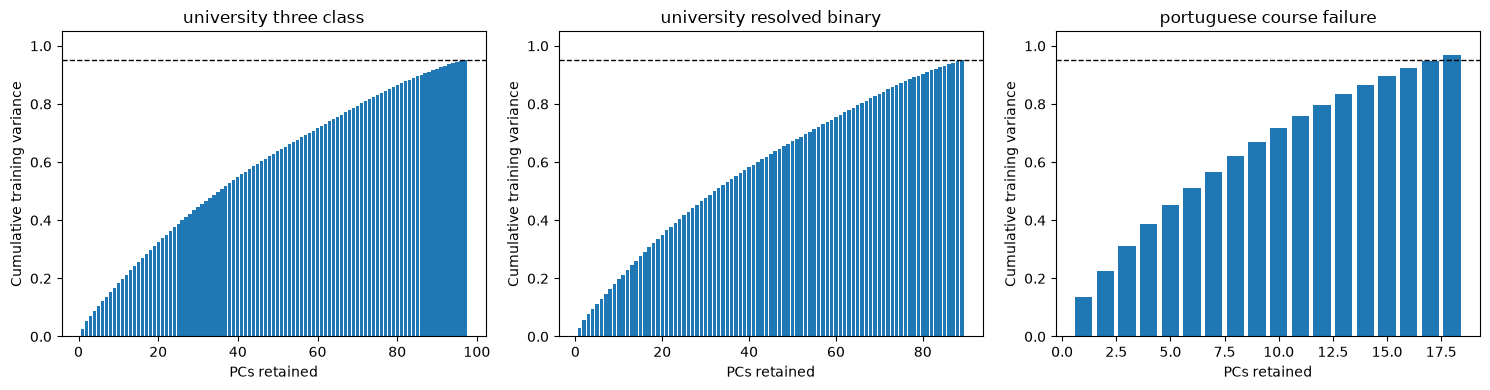

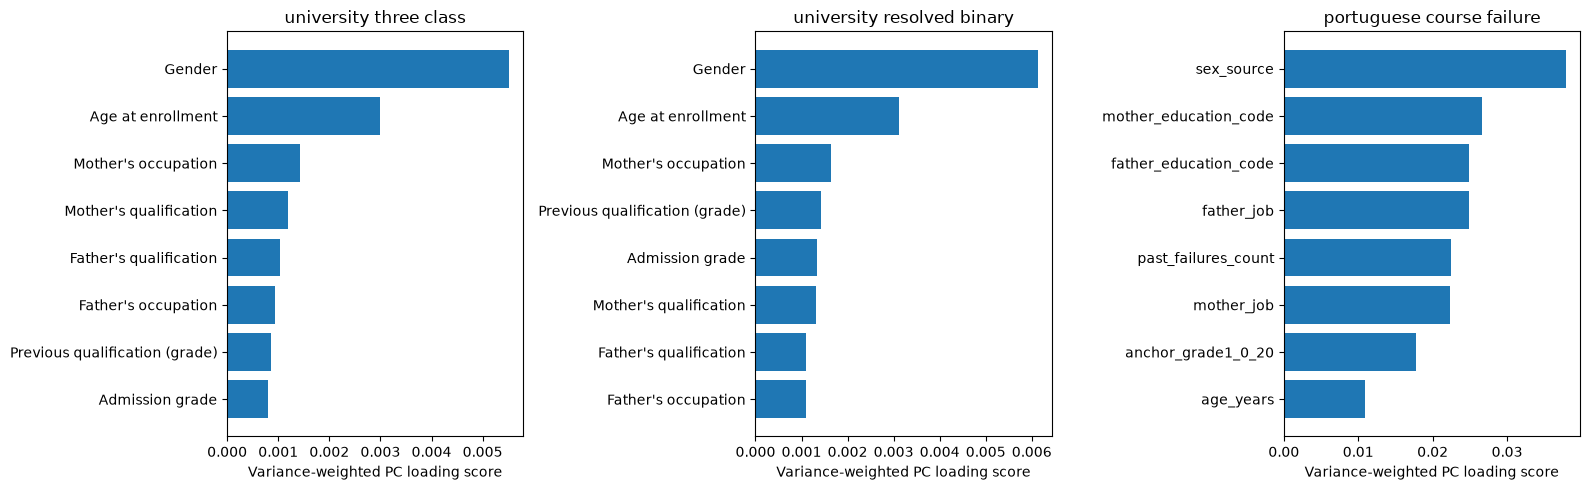

In [8]:
PCA_VARIANCE=0.95
RANK_PCS=8
KEEP_FRACTION=0.60

def prep_pca_ranking(cfg,features):
    parts=cfg['parts']; source=cfg['dataset']
    prep=preprocessing(features,source)
    X={'train':np.asarray(prep.fit_transform(parts['train'][features]),dtype=np.float32)}
    X.update({s:np.asarray(prep.transform(parts[s][features]),dtype=np.float32)
              for s in ('validation','test')})
    assert all(np.isfinite(z).all() for z in X.values())
    scaler=StandardScaler().fit(X['train'])
    Z={s:scaler.transform(X[s]).astype(np.float32) for s in X}
    pca=PCA(n_components=PCA_VARIANCE,svd_solver='full')
    P={'train':pca.fit_transform(Z['train']).astype(np.float32)}
    P.update({s:pca.transform(Z[s]).astype(np.float32) for s in ('validation','test')})
    groups=encoded_index_groups(prep,features,source)
    k=min(RANK_PCS,pca.n_components_)
    weight=(pca.components_[:k]**2*pca.explained_variance_ratio_[:k,None]).sum(axis=0)
    ranking=pd.DataFrame([{'column':field,'encoded_count':len(ix),
       'pca_variance_score':float(weight[ix].mean())} for field,ix in groups.items()])
    ranking=ranking.sort_values('pca_variance_score',ascending=False).reset_index(drop=True)
    return {'preprocessor':prep,'raw':X,'pca':P,'pca_fit':pca,'ranking':ranking,
            'pca_dimensions':P['train'].shape[1], 'encoded_dimensions':X['train'].shape[1],
            'explained_variance':float(pca.explained_variance_ratio_.sum())}

studies={}; dimension_rows=[]
for task,cfg in tasks.items():
    for subset,_ in SUBSETS:
        fields=cols_for_subset(cfg['dataset'],subset)
        study=prep_pca_ranking(cfg,fields)
        studies[(task,subset)]=study
        dimension_rows.append({'task':task,'feature_set':subset,'source_columns':len(fields),
            'encoded_dimensions':study['encoded_dimensions'],
            'pca_dimensions':study['pca_dimensions'],
            'train_variance_explained':study['explained_variance']})
        rankings=study['ranking'].copy()
        rankings.insert(0,'feature_set',subset);rankings.insert(0,'task',task)
        rankings.to_csv(OUTPUT_DIR/f'{task}_{subset}_pca_feature_ranking.csv',index=False)
dims=pd.DataFrame(dimension_rows)
dims.to_csv(OUTPUT_DIR/'pca_dimension_summary.csv',index=False)
display(dims)
fig,axs=plt.subplots(1,3,figsize=(15,4))
for ax,(task,cfg) in zip(axs,tasks.items()):
    s=studies[(task,'common_plus_cautious')]
    p=s['pca_fit']
    ax.bar(range(1,len(p.explained_variance_ratio_)+1),np.cumsum(p.explained_variance_ratio_))
    ax.axhline(.95,color='black',linestyle='--',linewidth=1)
    ax.set(title=task.replace('_',' '),xlabel='PCs retained',ylabel='Cumulative training variance',ylim=(0,1.05))
plt.tight_layout();plt.savefig(OUTPUT_DIR/'pca_cumulative_variance.png',dpi=150);plt.show()
fig,axs=plt.subplots(1,3,figsize=(16,5))
for ax,(task,cfg) in zip(axs,tasks.items()):
    r=studies[(task,'common_plus_cautious')]['ranking'].sort_values('pca_variance_score')
    ax.barh(r['column'],r['pca_variance_score'])
    ax.set(title=task.replace('_',' '),xlabel='Variance-weighted PC loading score')
plt.tight_layout();plt.savefig(OUTPUT_DIR/'pca_source_feature_relevance.png',dpi=150);plt.show()

## 8. Train neural networks for each feature set; compare raw vs PCA

All splits are fixed, and each representation is train-fitted. `common_plus_exploratory` uses speculative cross-domain analogues and should **not** be described as a validated harmonized feature space. The best epoch is chosen from the **validation** split, and all test results are diagnostic once, not used to retune this notebook.

In [9]:
results=[]; histories={}; final_test_pred={}
for task,cfg in tasks.items():
    for subset,_ in SUBSETS:
        s=studies[(task,subset)]
        for representation, X in [('original_encoded',s['raw']),('pca_95pct',s['pca'])]:
            model,best_epoch,hist=fit_nn(X,cfg['ys'],len(cfg['labels']))
            histories[(task,subset,representation)]=hist
            print(f'{task:29s} {subset:25s} {representation:17s} epoch={best_epoch:2d}',flush=True)
            for part in ('validation','test'):
                pred=probas(model,X[part])
                results.append({'task':task,'feature_set':subset,'representation':representation,
                    'split':part,'encoded_dim':X['train'].shape[1],
                    'best_epoch':best_epoch, **metrics(cfg['ys'][part],pred)})
                if part=='test': final_test_pred[(task,subset,representation)]=pred
metrics_df=pd.DataFrame(results)
metrics_df.to_csv(OUTPUT_DIR/'nn_feature_group_comparison.csv',index=False)
display(metrics_df.loc[metrics_df.split=='test',
  ['task','feature_set','representation','encoded_dim','positive_pr_auc','positive_roc_auc',
   'macro_f1','positive_recall','positive_brier']].round(4))

university_three_class        common_only               original_encoded  epoch= 8
university_three_class        common_only               pca_95pct         epoch= 3
university_three_class        common_plus_cautious      original_encoded  epoch= 8
university_three_class        common_plus_cautious      pca_95pct         epoch= 4
university_three_class        common_plus_exploratory   original_encoded  epoch= 7
university_three_class        common_plus_exploratory   pca_95pct         epoch= 3
university_three_class        full_eligible             original_encoded  epoch= 9
university_three_class        full_eligible             pca_95pct         epoch= 4
university_resolved_binary    common_only               original_encoded  epoch=14
university_resolved_binary    common_only               pca_95pct         epoch= 3
university_resolved_binary    common_plus_cautious      original_encoded  epoch= 4
university_resolved_binary    common_plus_cautious      pca_95pct         epoch= 3
univ

,task,feature_set,representation,encoded_dim,positive_pr_auc,positive_roc_auc,macro_f1,positive_recall,positive_brier
1,university_three_class,common_only,original_encoded,125,0.5602,0.7233,0.4140,0.5486,0.1852
3,university_three_class,common_only,pca_95pct,95,0.5267,0.6899,0.3796,0.4028,0.1949
5,university_three_class,common_plus_cautious,original_encoded,127,0.5591,0.7301,0.4150,0.5868,0.1852
7,university_three_class,common_plus_cautious,pca_95pct,97,0.5429,0.7099,0.4159,0.5486,0.1900
9,university_three_class,common_plus_exploratory,original_encoded,131,0.5823,0.7590,0.4173,0.5938,0.1785
11,university_three_class,common_plus_exploratory,pca_95pct,98,0.5405,0.7281,0.3982,0.5000,0.1873
13,university_three_class,full_eligible,original_encoded,209,0.6269,0.7679,0.4421,0.5799,0.1725
15,university_three_class,full_eligible,pca_95pct,156,0.5757,0.7372,0.4428,0.5833,0.1827
17,university_resolved_binary,common_only,original_encoded,118,0.6486,0.7359,0.6766,0.5174,0.1958
19,university_resolved_binary,common_only,pca_95pct,88,0.6019,0.6977,0.6416,0.3993,0.2085


## Additional experiment: PCA-ranked original feature selection

For only the `common_plus_cautious` feature group, retain the top 60% original fields according to **train PCA** (minimum two). Refit a raw-feature preprocessor and MLP. This tests whether PCA rankings help **feature selection**, as distinct from training on PC values.

In [10]:
for task,cfg in tasks.items():
    base=studies[(task,'common_plus_cautious')]
    selected=base['ranking'].head(max(2,int(np.ceil(KEEP_FRACTION*len(base['ranking'])))))['column'].tolist()
    print(task,'PCA-selected original variables:',selected)
    prep=preprocessing(selected,cfg['dataset'])
    X={'train':np.asarray(prep.fit_transform(cfg['parts']['train'][selected]),dtype=np.float32)}
    X.update({part:np.asarray(prep.transform(cfg['parts'][part][selected]),dtype=np.float32)
       for part in ('validation','test')})
    model,epoch,hist=fit_nn(X,cfg['ys'],len(cfg['labels']))
    histories[(task,'pca_ranked_subset','original_encoded')]=hist
    for part in ('validation','test'):
        p=probas(model,X[part])
        results.append({'task':task,'feature_set':'pca_ranked_subset','representation':'original_encoded',
          'split':part,'encoded_dim':X['train'].shape[1],
          'best_epoch':epoch,**metrics(cfg['ys'][part],p)})
        if part=='test':final_test_pred[(task,'pca_ranked_subset','original_encoded')]=p
    pd.DataFrame({'column':selected}).to_csv(OUTPUT_DIR/f'{task}_pca_selected_columns.csv',index=False)
metrics_df=pd.DataFrame(results)
metrics_df.to_csv(OUTPUT_DIR/'nn_feature_group_comparison.csv',index=False)

university_three_class PCA-selected original variables: ['Gender', 'Age at enrollment', "Mother's occupation", "Mother's qualification", "Father's qualification"]
university_resolved_binary PCA-selected original variables: ['Gender', 'Age at enrollment', "Mother's occupation", 'Previous qualification (grade)', 'Admission grade']
portuguese_course_failure PCA-selected original variables: ['sex_source', 'mother_education_code', 'father_education_code', 'father_job', 'past_failures_count']


## Prediction-relevance comparisons and visualizations

**Predictive relevance** is assessed via **validation/test changes in PR-AUC, F1, Brier** when feature groups are added to the *same architecture*, not from PCA scores alone. Comparisons across three-class and binary tasks are not directly interchangeable because their populations and label spaces differ. The initial baseline uses common-only original encoded data.

Test differences are exploratory (one split, one initialization). Treat validation rankings as the appropriate basis for selecting a feature set, and leave the final test split untouched for any future tuning.

VALIDATION-selected configurations, and their single held-out test scores:


/var/folders/wp/gc0pmmnx4d91zc8_lsf9s99h0000gn/T/ipykernel_6422/3356812083.py:10: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  report['chosen_on_validation']=report['chosen_on_validation'].astype('boolean').fillna(False).astype(bool)


,task,feature_set,representation,positive_pr_auc,positive_roc_auc,macro_f1,positive_brier
6,university_three_class,full_eligible,original_encoded,0.6269,0.7679,0.4421,0.1725
14,university_resolved_binary,full_eligible,original_encoded,0.6961,0.7744,0.6991,0.1852
20,portuguese_course_failure,common_plus_exploratory,original_encoded,0.6356,0.9302,0.7341,0.0809


ALL neural-network test results and changes versus common-only:


,task,feature_set,representation,positive_pr_auc,delta_positive_pr_auc_vs_common,macro_f1,positive_brier
1,university_three_class,common_only,original_encoded,0.5602,0.0000,0.4140,0.1852
3,university_three_class,common_only,pca_95pct,0.5267,-0.0335,0.3796,0.1949
5,university_three_class,common_plus_cautious,original_encoded,0.5591,-0.0011,0.4150,0.1852
7,university_three_class,common_plus_cautious,pca_95pct,0.5429,-0.0173,0.4159,0.1900
9,university_three_class,common_plus_exploratory,original_encoded,0.5823,0.0221,0.4173,0.1785
11,university_three_class,common_plus_exploratory,pca_95pct,0.5405,-0.0197,0.3982,0.1873
13,university_three_class,full_eligible,original_encoded,0.6269,0.0667,0.4421,0.1725
15,university_three_class,full_eligible,pca_95pct,0.5757,0.0155,0.4428,0.1827
17,university_resolved_binary,common_only,original_encoded,0.6486,0.0000,0.6766,0.1958
19,university_resolved_binary,common_only,pca_95pct,0.6019,-0.0467,0.6416,0.2085


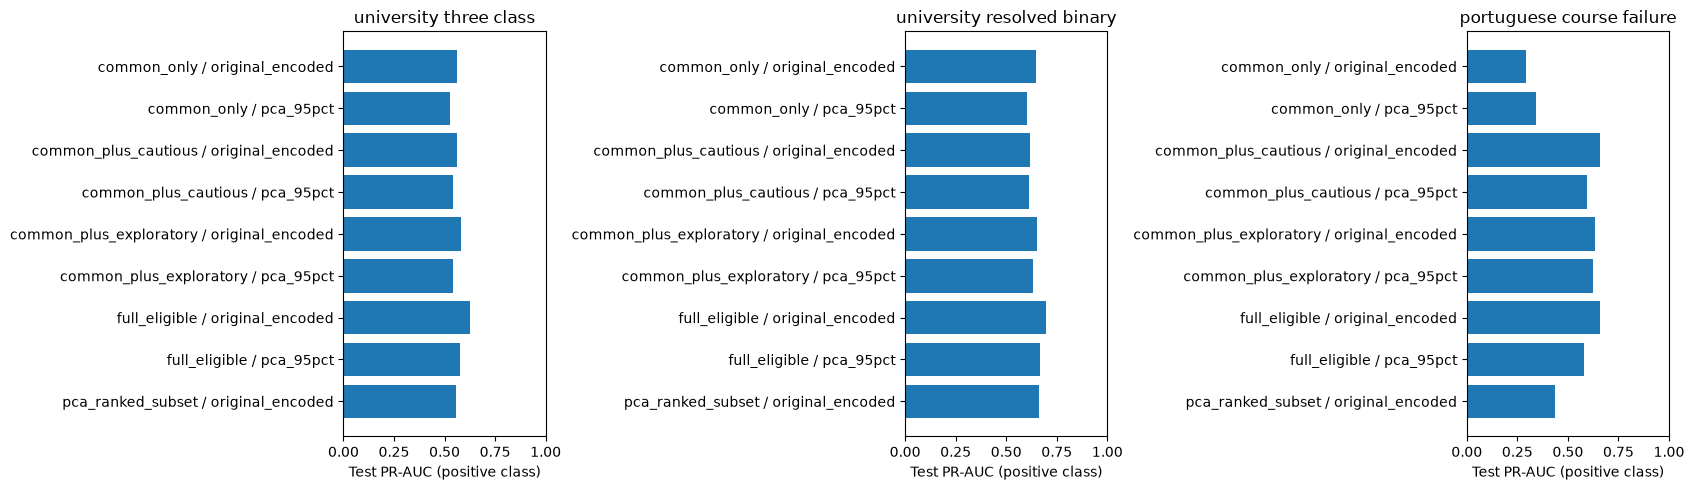

Caveat: winning variant selection should be based on validation; do not retune from these test plots.


In [11]:
test=metrics_df.loc[metrics_df.split=='test'].copy()
val=metrics_df.loc[metrics_df.split=='validation'].copy()
reference=test.query('feature_set=="common_only" and representation=="original_encoded"').set_index('task')
for measure in ['positive_pr_auc','positive_roc_auc','macro_f1','positive_brier']:
    test[f'delta_{measure}_vs_common']=test.apply(lambda row:row[measure]-reference.loc[row['task'],measure],axis=1)
test.to_csv(OUTPUT_DIR/'nn_test_deltas_vs_common.csv',index=False)
validation_best=val.sort_values(['task','positive_pr_auc','positive_brier'],ascending=[True,False,True]).groupby('task').head(1)
report=test.merge(validation_best[['task','feature_set','representation']].assign(chosen_on_validation=True),
                  how='left',on=['task','feature_set','representation'])
report['chosen_on_validation']=report['chosen_on_validation'].astype('boolean').fillna(False).astype(bool)
report.to_csv(OUTPUT_DIR/'nn_test_validation_selected.csv',index=False)
print('VALIDATION-selected configurations, and their single held-out test scores:')
display(report.loc[report.chosen_on_validation,
 ['task','feature_set','representation','positive_pr_auc','positive_roc_auc','macro_f1','positive_brier']].round(4))
print('ALL neural-network test results and changes versus common-only:')
display(test[['task','feature_set','representation','positive_pr_auc','delta_positive_pr_auc_vs_common',
              'macro_f1','positive_brier']].round(4))
fig,axs=plt.subplots(1,3,figsize=(17,5))
for ax,(task,cfg) in zip(axs,tasks.items()):
    d=test.loc[test.task==task]
    names=[f'{r.feature_set} / {r.representation}' for r in d.itertuples()]
    ax.barh(names,d.positive_pr_auc)
    ax.set(title=task.replace('_',' '),xlabel='Test PR-AUC (positive class)',xlim=(0,1))
    ax.invert_yaxis()
plt.tight_layout();plt.savefig(OUTPUT_DIR/'test_pr_auc_by_feature_group.png',dpi=160);plt.show()
print('Caveat: winning variant selection should be based on validation; do not retune from these test plots.')

## Optional qualitative feature group overview and report tables

The full catalog may be exported for the research report. Some unique features are **not** eligible for early prediction (IDs, later outcomes, assumed/derived simulator state). The final model's feature values should not be construed as causal explanations of withdrawal. PCA findings cannot establish that a variable prevents dropout.

In [13]:
summary=[]
for ds in ('school','university'):
    fields=catalog[(catalog.dataset==ds)&(catalog.category.isin(['common','partial_cautious','partial_weak','unique']))]
    for group,d in fields.groupby('category',sort=False):
        summary.append({'dataset':ds,'category':group,
                        'n_columns':len(d),'columns':', '.join(d.column.tolist())})
report_features=pd.DataFrame(summary)
report_features.to_csv(OUTPUT_DIR/'report_feature_summary.csv',index=False)
display(report_features)
summary_text=['# Common features and PCA/neural-network analysis — result summary','',
 '**Outcome warning:** school target = course failure, university target = enrollment status or resolved dropout vs graduation.',
 'PCA variance relevance is not predictive/causal importance; weak partial indicators are not equivalent fields.','',
 '## Validation-selected model per task',
 report.loc[report.chosen_on_validation,['task','feature_set','representation','positive_pr_auc','positive_roc_auc','macro_f1','positive_brier']].to_markdown(index=False),
 '', '## Feature category inventory', report_features.to_markdown(index=False),
 '', 'This notebook used original archive splits, imputation/encoding/PCA fit only on training data, and identical NN architecture.']
(OUTPUT_DIR/'FINDINGS.md').write_text('\n'.join(summary_text),encoding='utf-8')
print('Output files:',len(list(OUTPUT_DIR.iterdir())))

,dataset,category,n_columns,columns
0,school,unique,15,"school_id, rural_residence, family_size_gt3, p..."
1,school,common,6,"age_years, sex_source, mother_education_code, ..."
2,school,partial_cautious,2,"past_failures_count, anchor_grade1_0_20"
3,school,partial_weak,2,"school_support_existing, no_home_internet"
4,university,common,6,"Age at enrollment, Mother's qualification, Fat..."
5,university,unique,12,"Application order, Unemployment rate, Inflatio..."
6,university,partial_cautious,2,"Previous qualification (grade), Admission grade"
7,university,partial_weak,2,"Educational special needs, Scholarship holder"


Output files: 27


## Interpretation and next research steps

1. **Different targets:** the Portuguese school outcome is course failure, **not permanent dropout**. Use no school-dropout claims from these supervised labels.
2. **Concept alignment:** six plausible common concepts have different codings and population meanings; PCA and networks are trained **separately**, never pooling university and school rows.
3. **Partials are conditional:** `anchor_grade1_0_20` versus `Admission grade` are not contemporaneous; school internet access versus university scholarship is **not** one shared poverty variable; needing support is **not** receiving support. Recheck field timing before any real deployment.
4. **No leakage:** `anchor_final_grade_0_20`, `G2`, `G3`, final absences, university first-/second-semester outcome fields, split/IDs, and synthetic hazard/response parameters remain outside inputs.
5. **PCA caveat:** principal components maximize variance, **not label discrimination**. Large PCA loading ≠ important predictor ≠ causal factor. Run supervised permutation or SHAP **after** selecting and freezing a meaningful model, with categorical group handling and subgroup error analysis.
6. **Small population caveat:** school data comes from two Portuguese schools with only 649 Portuguese anchors; assess uncertainty with repeated training seeds, new school cohorts and sensible confidence intervals. Do not optimize repeatedly on test scores.
7. **Recommendation for dropout-prevention allocation:** use the school-based simulation for sequential allocation.